## Install and load libraries

In [1]:
import sys
if 'google.colab' in sys.modules:
  !pip install -q dtreeviz
!pip install interpret six graphviz pydotplus

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 44.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 89.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 124.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.1/800.1 kB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 131.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.6/270.6 kB 22.9 MB/s eta 0:00:00
  Created wheel for dash-cytoscape: filename=dash_cytoscape-1.0.2-py3-none-any.whl size=4010811 sha256=02e58b06697c3b988ad60edaa7629b68448d058d3c818373cf646b49711744d2

In [5]:
# Load libraries
import pandas as pd
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
# Import train_test_split function
from sklearn.model_selection import train_test_split
# Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Export Graph as DotFile
from sklearn.tree import export_graphviz
# For using the DotFile
from six import StringIO
# Display the Tree as Image in Jupyter
from IPython.display import Image
# Convert DotFile to PNG
import pydotplus

## Load the Diabetes dataset

In [6]:
pima = pd.read_csv("https://bit.ly/PimaIDD")

In [7]:
feature_cols = pima.columns.values.tolist()[:-1]
X = pima[feature_cols]
y = pima.Outcome

<h2>Explore the dataset</h2>

500 non-diabetic and 268 diabetic patients.

In [8]:
from interpret import show
from interpret.data import ClassHistogram

hist = ClassHistogram().explain_data(X, y, name='Train Data')
show(hist)

Spare 30% of data for test.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=411)

# Train and plot a classification tree

Use the `interpretml` wrapper around scikit-learns's `DecisionTreeClassifier`, `ClassificationTree`.

In [10]:
from interpret.glassbox import ClassificationTree
tree = ClassificationTree()
tree.fit(X_train, y_train)

### Exercises / questions

- What is the summary for the BMI feature?
- What about Glucose?
- And Diabetes Pedigree Function?

Notes:

- The plot does not display the class of each leaf, nor the number of instances within.
- We do not have a global importance score per feature.
- We can:
    - zoom into the tree.
    - move nodes around.

In [11]:
from interpret import show
tree_global = tree.explain_global(name='Tree')
show(tree_global)

Note that the BMI feature seems to have a "critical" value, of around 27, which appears in three subtrees. Indeed, this value is close to the threshold between normal and overweight (see [](https://www.nhlbi.nih.gov/health/educational/lose_wt/BMI/bmi_tbl.pdf)). The other BMI threshold is around 45, which corresponds to extreme obesity.

Alternatively, we can use scikit-learn's built-in plotting. Now we get more information about the nodes; on the other hand, not easy, for example, to check whether a feature is missing from the tree.

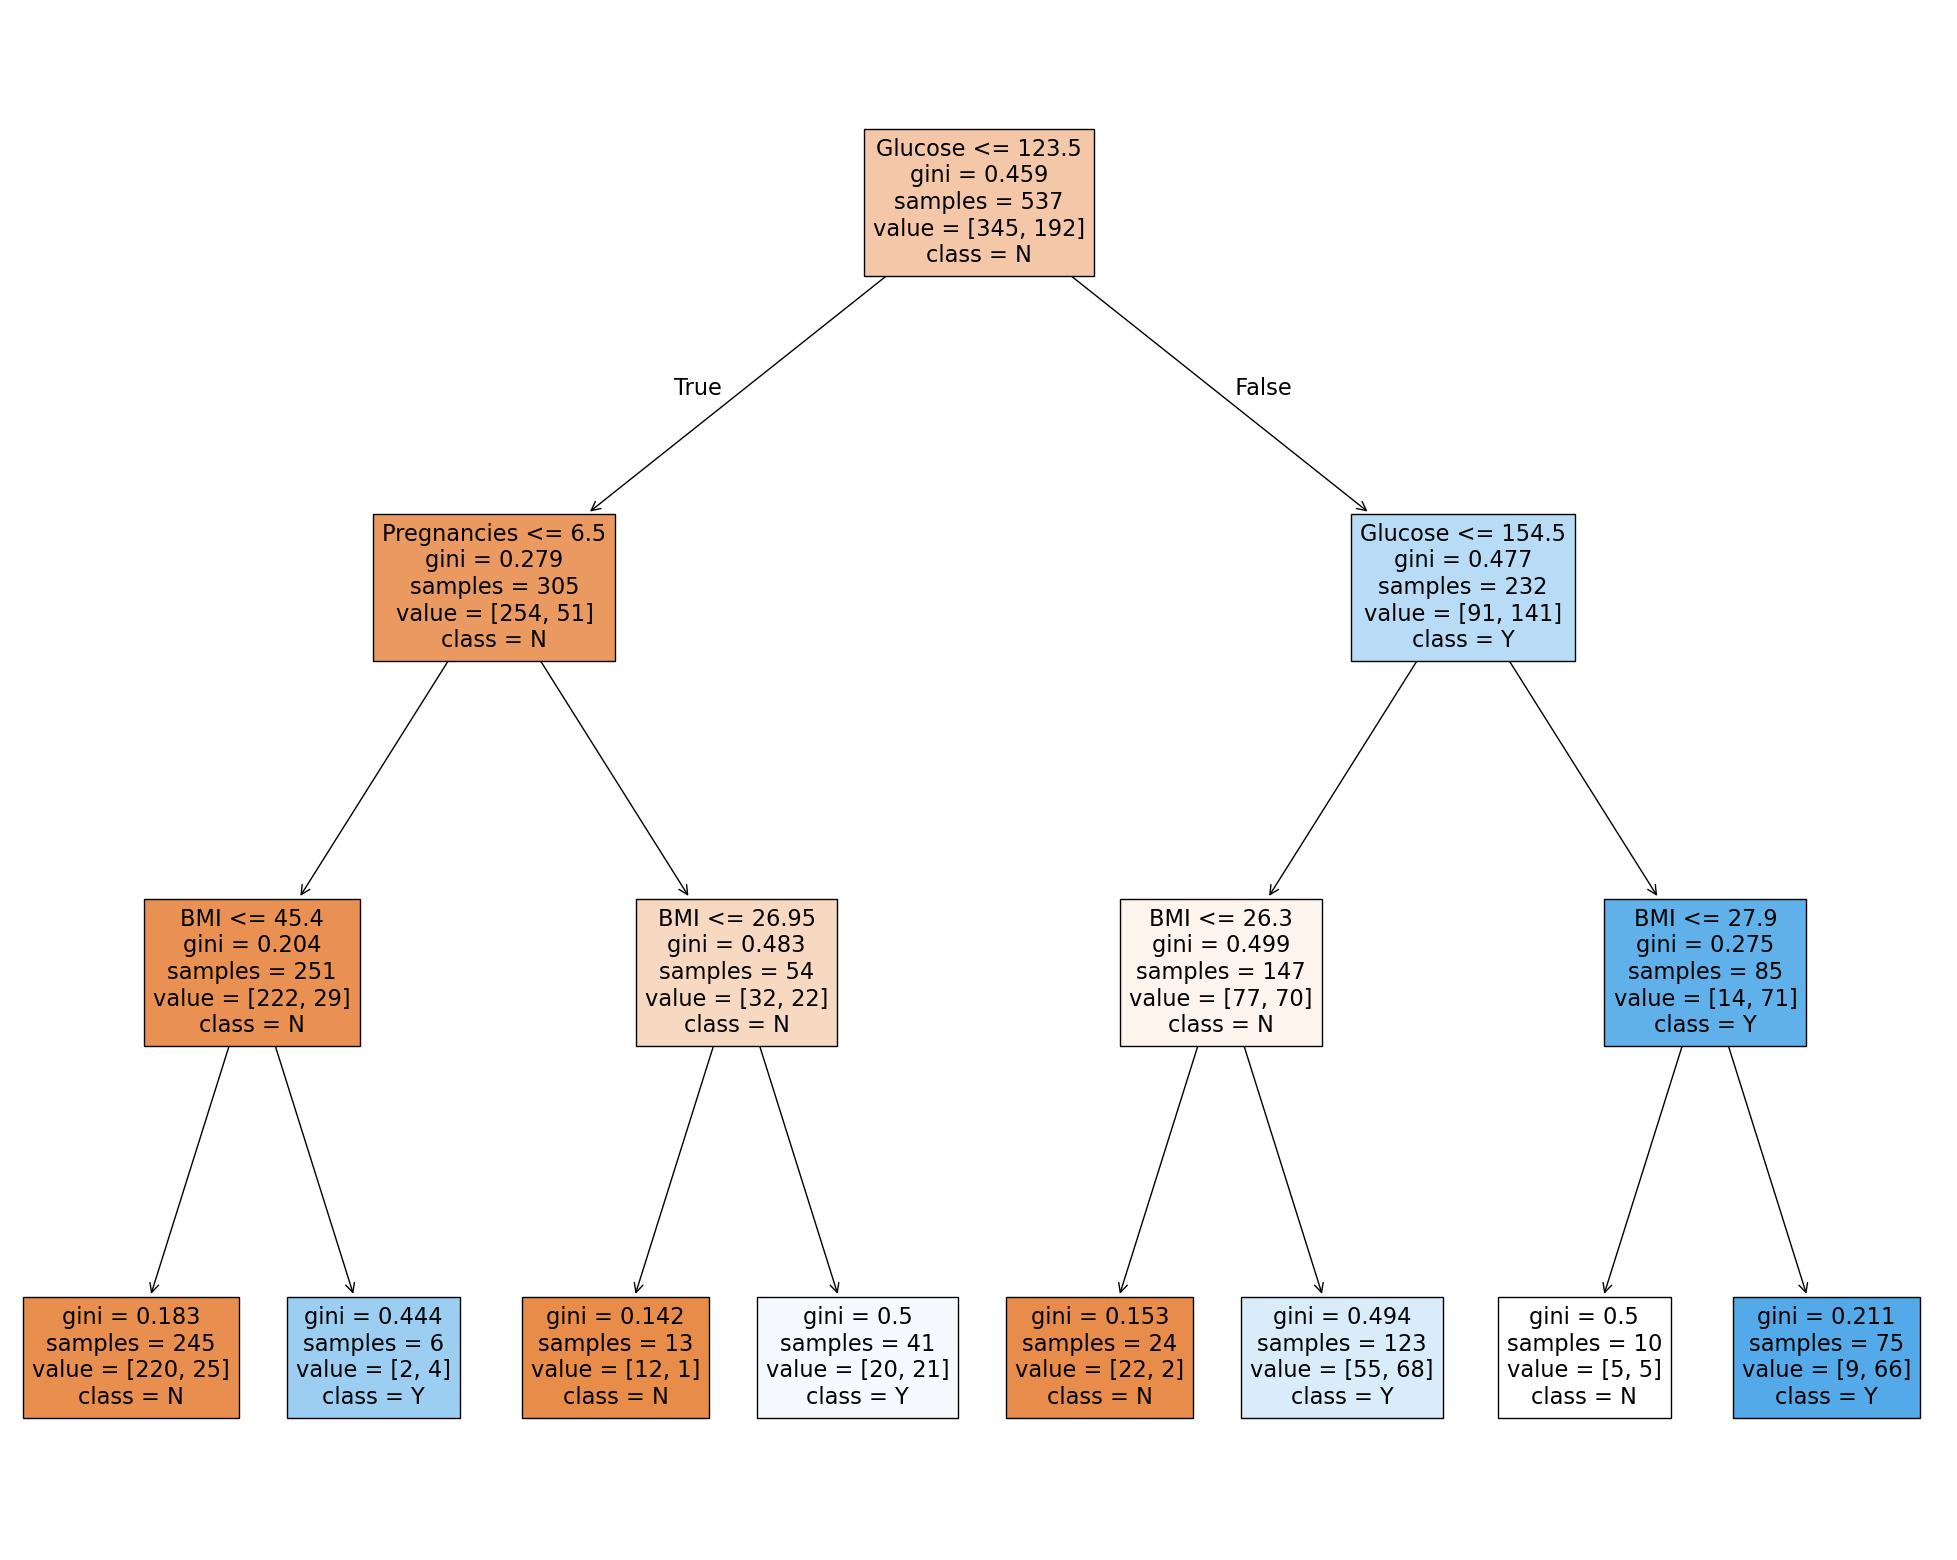

In [12]:
from matplotlib import pyplot as plt
from sklearn.tree import plot_tree
fig = plt.figure(figsize=(25,20))
_ = plot_tree(tree._model(),
                   feature_names=feature_cols,
                   class_names=['N', 'Y'],
                   filled=True)

We can get more elaborate plots with graphiviz and dtreeviz:

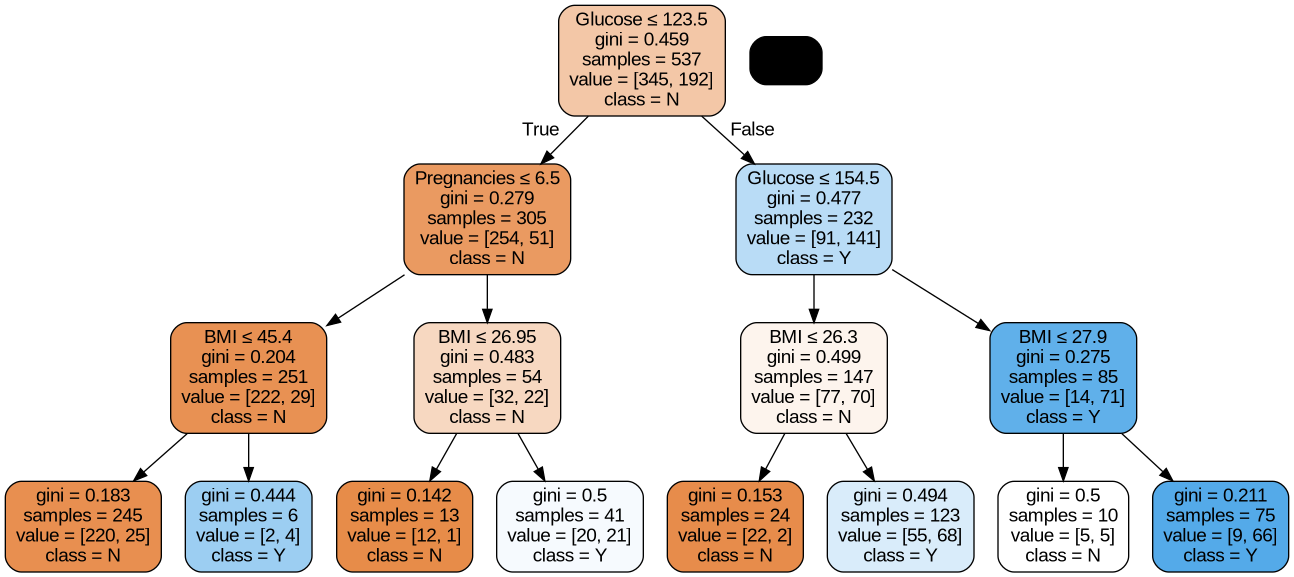

In [13]:
dot_data = StringIO()
export_graphviz(tree._model(), out_file=dot_data,
                filled=True, rounded=True,
                special_characters=True, feature_names=feature_cols,
                class_names=['N', 'Y'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())

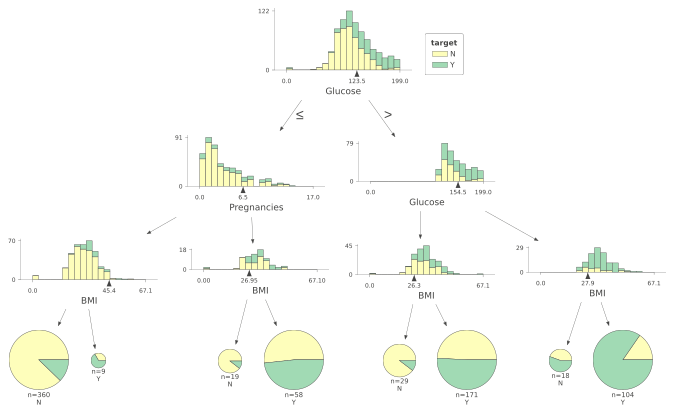

In [14]:
import dtreeviz
dtreeviz_model = dtreeviz.model(tree._model(), X, y,
                                feature_names=feature_cols,
                                target_name="target",
                                class_names=['N', 'Y'])
viz = dtreeviz_model.view()
viz

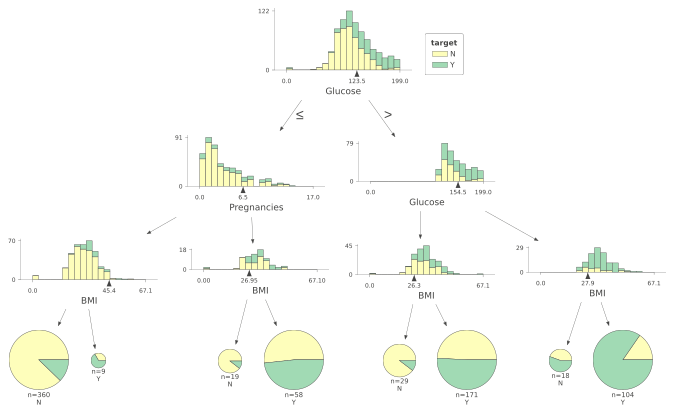

In [15]:
from interpret.glassbox import ClassificationTree
import dtreeviz # Corrected import

tree = ClassificationTree()
tree.fit(X_train, y_train)

# Using the new recommended dtreeviz API
dtreeviz_model = dtreeviz.model(tree._model(), X, y,
                                feature_names=feature_cols,
                                target_name="target",
                                class_names=['N', 'Y'])
viz = dtreeviz_model.view()
viz

scikit-learn gives us feature importance measures; these are computed as the (normalized) total reduction of the criterion brought by that feature. It is also known as the Gini importance. However: impurity-based feature importances can be misleading for high cardinality features (many unique values).

In [ ]:
tree._model().feature_importances_

Note that, due to tree instability, the absence or low importance score for some variable does not mean it is not predictive. It is simply not used in this particular tree.

## Evaluate the model

In [16]:
from sklearn.metrics import roc_auc_score
print(f"DT AUC: {roc_auc_score(y_test, tree.predict_proba(X_test)[:,1]):.2f}")

DT AUC: 0.73


The model is predicting both positives and negatives.

In [17]:
metrics.confusion_matrix(y_test, tree.predict(X_test))

array([[108,  47],
       [ 26,  50]])

Compare to blackbox and glassbox models.

In [18]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from interpret.glassbox import ExplainableBoostingClassifier

# Train
gb_clf = GradientBoostingClassifier().fit(X_train, y_train)
rf_clf = RandomForestClassifier().fit(X_train, y_train)

# Print AUC values
print(f"Gradient Boosting AUC: {roc_auc_score(y_test, gb_clf.predict_proba(X_test)[:,1]):.2f}")
print(f"Random Forest AUC: {roc_auc_score(y_test, rf_clf.predict_proba(X_test)[:,1]):.2f}")

from interpret.glassbox import LogisticRegression, ClassificationTree

seed = 42
lr = LogisticRegression(random_state=seed, penalty='l1', solver='liblinear').fit(X_train, y_train)
ebm = ExplainableBoostingClassifier().fit(X_train, y_train)

# Print AUC values
print(f"Logistic Regression AUC: {roc_auc_score(y_test, lr.predict_proba(X_test)[:,1]):.2f}")
print(f"EBM AUC: {roc_auc_score(y_test, ebm.predict_proba(X_test)[:,1]):.2f}")

Gradient Boosting AUC: 0.84
Random Forest AUC: 0.83
Logistic Regression AUC: 0.82
EBM AUC: 0.84


### Exercises

- Change the train/test split and re-learn the depth-3 tree. How similar? What about predictive performance? In order to redo the split, either remove or change the random seed.

## Change parameters

`ClassificationTree` learns a tree of at most depth 3. Let's drop any limits on depth and visualize and evaluate the tree.

- Is the tree interpretable?
- Does it predict better or worse than our previous tree?
- How many times does Glucose appear in the tree?

In [ ]:
tree = ClassificationTree(max_depth = None)
tree.fit(X_train, y_train)
print(f"DT AUC: {roc_auc_score(y_test, tree.predict_proba(X_test)[:,1]):.2f}")
tree_global = tree.explain_global()
show(tree_global)

Set min leaf size to 20, `min_samples_leaf=20`

- How well does the tree perform on test data?
- What are some differences with respect to our original tree?

Note that we could have many very different, yet similarly performing, trees.

In [ ]:
tree = ClassificationTree(min_samples_leaf = 20)
tree.fit(X_train, y_train)
print(f"DT AUC: {roc_auc_score(y_test, tree.predict_proba(X_test)[:,1]):.2f}")
tree_global = tree.explain_global(name='Tree')
show(tree_global)

## Local explanation

In [19]:
tree_local = tree.explain_local(X_test[:5], y_test[:5], name='tree')
show(tree_local)

### Questions

- To which leaves were the first 5 test instances assigned?
- How could we identify similar instances?

## Extract rules

In [20]:
from sklearn.tree import export_text
print(export_text(tree._model(), feature_names=feature_cols))

|--- Glucose <= 123.50
|   |--- Pregnancies <= 6.50
|   |   |--- BMI <= 45.40
|   |   |   |--- class: 0
|   |   |--- BMI >  45.40
|   |   |   |--- class: 1
|   |--- Pregnancies >  6.50
|   |   |--- BMI <= 26.95
|   |   |   |--- class: 0
|   |   |--- BMI >  26.95
|   |   |   |--- class: 1
|--- Glucose >  123.50
|   |--- Glucose <= 154.50
|   |   |--- BMI <= 26.30
|   |   |   |--- class: 0
|   |   |--- BMI >  26.30
|   |   |   |--- class: 1
|   |--- Glucose >  154.50
|   |   |--- BMI <= 27.90
|   |   |   |--- class: 0
|   |   |--- BMI >  27.90
|   |   |   |--- class: 1



Format them as logical implications (code from <https://mljar.com/blog/extract-rules-decision-tree/>).

In [21]:
from sklearn.tree import _tree
def get_rules(tree, feature_names, class_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]

    paths = []
    path = []

    def recurse(node, path, paths):

        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            p1, p2 = list(path), list(path)
            p1 += [f"({name} <= {np.round(threshold, 3)})"]
            recurse(tree_.children_left[node], p1, paths)
            p2 += [f"({name} > {np.round(threshold, 3)})"]
            recurse(tree_.children_right[node], p2, paths)
        else:
            path += [(tree_.value[node], tree_.n_node_samples[node])]
            paths += [path]

    recurse(0, path, paths)

    # sort by samples count
    samples_count = [p[-1][1] for p in paths]
    ii = list(np.argsort(samples_count))
    paths = [paths[i] for i in reversed(ii)]

    rules = []
    for path in paths:
        rule = "if "

        for p in path[:-1]:
            if rule != "if ":
                rule += " and "
            rule += str(p)
        rule += " then "
        if class_names is None:
            rule += "response: "+str(np.round(path[-1][0][0][0],3))
        else:
            classes = path[-1][0][0]
            l = np.argmax(classes)
            rule += f"class: {class_names[l]} (proba: {np.round(100.0*classes[l]/np.sum(classes),2)}%)"
        rule += f" | based on {path[-1][1]:,} samples"
        rules += [rule]

    return rules


In [22]:
import numpy as np
rules = get_rules(tree._model(), feature_cols, ['N','Y'])
for r in rules:
    print(r)

if (Glucose <= 123.5) and (Pregnancies <= 6.5) and (BMI <= 45.4) then class: N (proba: 89.8%) | based on 245 samples
if (Glucose > 123.5) and (Glucose <= 154.5) and (BMI > 26.3) then class: Y (proba: 55.28%) | based on 123 samples
if (Glucose > 123.5) and (Glucose > 154.5) and (BMI > 27.9) then class: Y (proba: 88.0%) | based on 75 samples
if (Glucose <= 123.5) and (Pregnancies > 6.5) and (BMI > 26.95) then class: Y (proba: 51.22%) | based on 41 samples
if (Glucose > 123.5) and (Glucose <= 154.5) and (BMI <= 26.3) then class: N (proba: 91.67%) | based on 24 samples
if (Glucose <= 123.5) and (Pregnancies > 6.5) and (BMI <= 26.95) then class: N (proba: 92.31%) | based on 13 samples
if (Glucose > 123.5) and (Glucose > 154.5) and (BMI <= 27.9) then class: N (proba: 50.0%) | based on 10 samples
if (Glucose <= 123.5) and (Pregnancies <= 6.5) and (BMI > 45.4) then class: Y (proba: 66.67%) | based on 6 samples


### Questions

- Could the rules be made more compact?

# Exercise: the Breast Cancer dataset

- Train a Decision Tree.
- Evaluate the tree and compare to blackbox and glassbox models.
- Is the variable "mean perimeter" used by the tree?
- Try to change the tree parameters to get a good balance between performance and interpretability.
- Identify the leaves to which the first 10 instances were assigned.

In [ ]:
from sklearn.datasets import load_breast_cancer

seed = 42
np.random.seed(seed)
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=seed)

